# CICIoT2023 — Exploratory Data Analysis (C1-T09)

Dataset: Neto et al. 2023, 33 attacks in 7 categories (DDoS, DoS, Recon,
Web-based, BruteForce, Spoofing, Mirai) + benign traffic, captured on a
105-device IoT topology.

Our copy: `data/raw/ciciot2023/CSV/` — one folder per attack class
(the folder name is the label; the per-category CSVs carry no label column),
plus `Benign_Final/` for normal traffic.

Questions this notebook must answer before Checkpoint 2:
1. What does one record look like (features, dtypes, missing values)?
2. How big is each attack class relative to benign?
3. Which classes are relevant to OUR testbed (MQTT/Wi-Fi smart devices)?
4. What do key features look like for benign vs attack traffic?

## 0 — setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("data/raw/ciciot2023/CSV")
if not ROOT.is_dir():
    REPO = Path.cwd()
    if REPO.name == "notebooks":
        REPO = REPO.parent.parent
    ROOT = REPO / "data" / "raw" / "ciciot2023" / "CSV"
assert ROOT.is_dir(), f"dataset not found at {ROOT} - check the download location"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1 — dataset inventory (file tree scan, no parsing)

In [2]:
rows = []
for folder in sorted(ROOT.iterdir()):
    if not folder.is_dir():
        continue
    files = list(folder.glob("*.csv"))
    mb = sum(f.stat().st_size for f in files) / 1e6
    rows.append({"folder": folder.name, "files": len(files), "size_mb": round(mb, 1)})
inventory = pd.DataFrame(rows).sort_values("size_mb", ascending=False).reset_index(drop=True)
inventory

,folder,files,size_mb
0,DDoS-ICMP_Flood,27,1326.3
1,DDoS-UDP_Flood,21,1025.0
2,DDoS-TCP_Flood,18,843.8
3,DDoS-SYN_Flood,16,774.3
4,DDoS-PSHACK_FLOOD,16,769.6
5,DDoS-RSTFINFLOOD,16,767.0
6,DDoS-SynonymousIP_Flood,14,674.6
7,DoS-UDP_Flood,17,605.4
8,DoS-TCP_Flood,11,505.3
9,DoS-SYN_Flood,8,390.6


`Benign_Final` is small relative to the total volume — expect a strong class
imbalance once everything is merged. That imbalance decision (undersampling /
class weights) belongs to Checkpoint 2, not here.

## 2 — schema: columns and dtypes (one benign + one attack file)

In [3]:
benign_file = ROOT / "Benign_Final" / "BenignTraffic.pcap.csv"
attack_file = ROOT / "DDoS-SYN_Flood" / "DDoS-SYN_Flood.pcap.csv"

benign_sample = pd.read_csv(benign_file, nrows=50_000)
attack_sample = pd.read_csv(attack_file, nrows=50_000)

same_schema = list(benign_sample.columns) == list(attack_sample.columns)
print("columns match across files:", same_schema)
print("n columns:", len(benign_sample.columns))
benign_sample.dtypes.to_frame("dtype").T

columns match across files: True
n columns: 39


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance
dtype,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,float64


## 3 — missing values and constants (on samples)

In [4]:
def quality_report(df, name):
    nulls = df.isna().sum()
    constant = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    print(f"{name}: rows={len(df)}, null_cells={int(nulls.sum())}, "
          f"constant_cols={len(constant)}")
    if nulls.sum():
        print(nulls[nulls > 0])
    print("constant columns:", constant)

quality_report(benign_sample, "benign")
quality_report(attack_sample, "DDoS-SYN_Flood")

benign: rows=50000, null_cells=8, constant_cols=2
Std         4
Variance    4
dtype: int64
constant columns: ['Telnet', 'SMTP']
DDoS-SYN_Flood: rows=50000, null_cells=0, constant_cols=3
constant columns: ['ece_flag_number', 'cwr_flag_number', 'Min']


## 4 — class sizes by folder (row counts, sampled smartly)

In [5]:
FULL_PARSE_LIMIT = 80e6   # parse fully only folders whose files are small enough

def folder_rows(folder):
    total = 0
    for f in folder.glob("*.csv"):
        size = f.stat().st_size
        if size <= FULL_PARSE_LIMIT:
            total += len(pd.read_csv(f, usecols=[0]))
        else:
            with open(f, "rb") as fh:
                total += sum(1 for _ in fh) - 1
    return total

counts = {}
for folder in ROOT.iterdir():
    if folder.is_dir():
        counts[folder.name] = folder_rows(folder)
counts = pd.Series(counts).sort_values(ascending=False)
counts.to_frame("rows")

,rows
DDoS-ICMP_Flood,7200501
DDoS-UDP_Flood,5412231
DDoS-TCP_Flood,4497649
DDoS-PSHACK_FLOOD,4094772
DDoS-SYN_Flood,4059179
DDoS-RSTFINFLOOD,4045279
DDoS-SynonymousIP_Flood,3598133
DoS-UDP_Flood,3072993
DoS-TCP_Flood,2671430
DoS-SYN_Flood,2028836


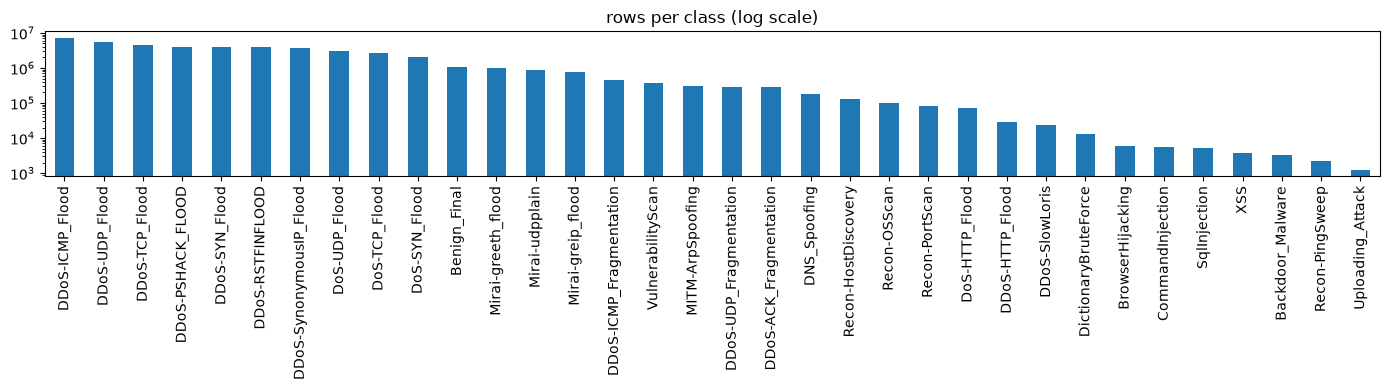

In [6]:
counts.plot(kind="bar", figsize=(14, 4), logy=True, title="rows per class (log scale)")
plt.tight_layout(); plt.show()

Log scale on purpose: DDoS/DoS/Mirai flooding classes dwarf Recon and Web
attacks by orders of magnitude. Binary (benign vs attack) evaluation will be
dominated by flooding; per-class metrics are the honest view.

## 5 — map folders to the 7 research categories

In [7]:
CATEGORY_MAP = {
    "DDoS": [c for c in counts.index if c.startswith("DDoS")],
    "DoS": [c for c in counts.index if c.startswith("DoS")],
    "Mirai": [c for c in counts.index if c.startswith("Mirai")],
    "Recon": [c for c in counts.index if c.startswith("Recon") or c in ("VulnerabilityScan", "PortScan", "PingScan", "OS_Scan", "UDPScan", "HostTracker", "HorizontallyPortScan")],
    "Web": [c for c in counts.index if c in ("SQLInjection", "CommandInjection", "Backdoor_Malware", "Uploading_Attack", "XSS", "BrowserHijacking")],
    "BruteForce": [c for c in counts.index if c in ("DictionaryBruteForce",)],
    "Spoofing": [c for c in counts.index if c in ("DNS_Spoofing", "MITMArpSpoofing")],
    "Benign": ["Benign_Final"],
}
for cat, members in CATEGORY_MAP.items():
    print(f"{cat:10s} {len(members):3d} classes  rows={int(sum(counts[m] for m in members)):>10,}")

DDoS        12 classes  rows=33,984,450
DoS          4 classes  rows= 7,845,120
Mirai        3 classes  rows= 2,634,054
Recon        5 classes  rows=   690,534
Web          5 classes  rows=    19,584
BruteForce   1 classes  rows=    13,064
Spoofing     1 classes  rows=   178,898
Benign       1 classes  rows= 1,098,191


Check against README_CSV.pdf in the dataset root — every class folder must land
in exactly one category. Any leftover names here mean the map needs fixing.

## 6 — benign vs attack feature distributions (sampled)

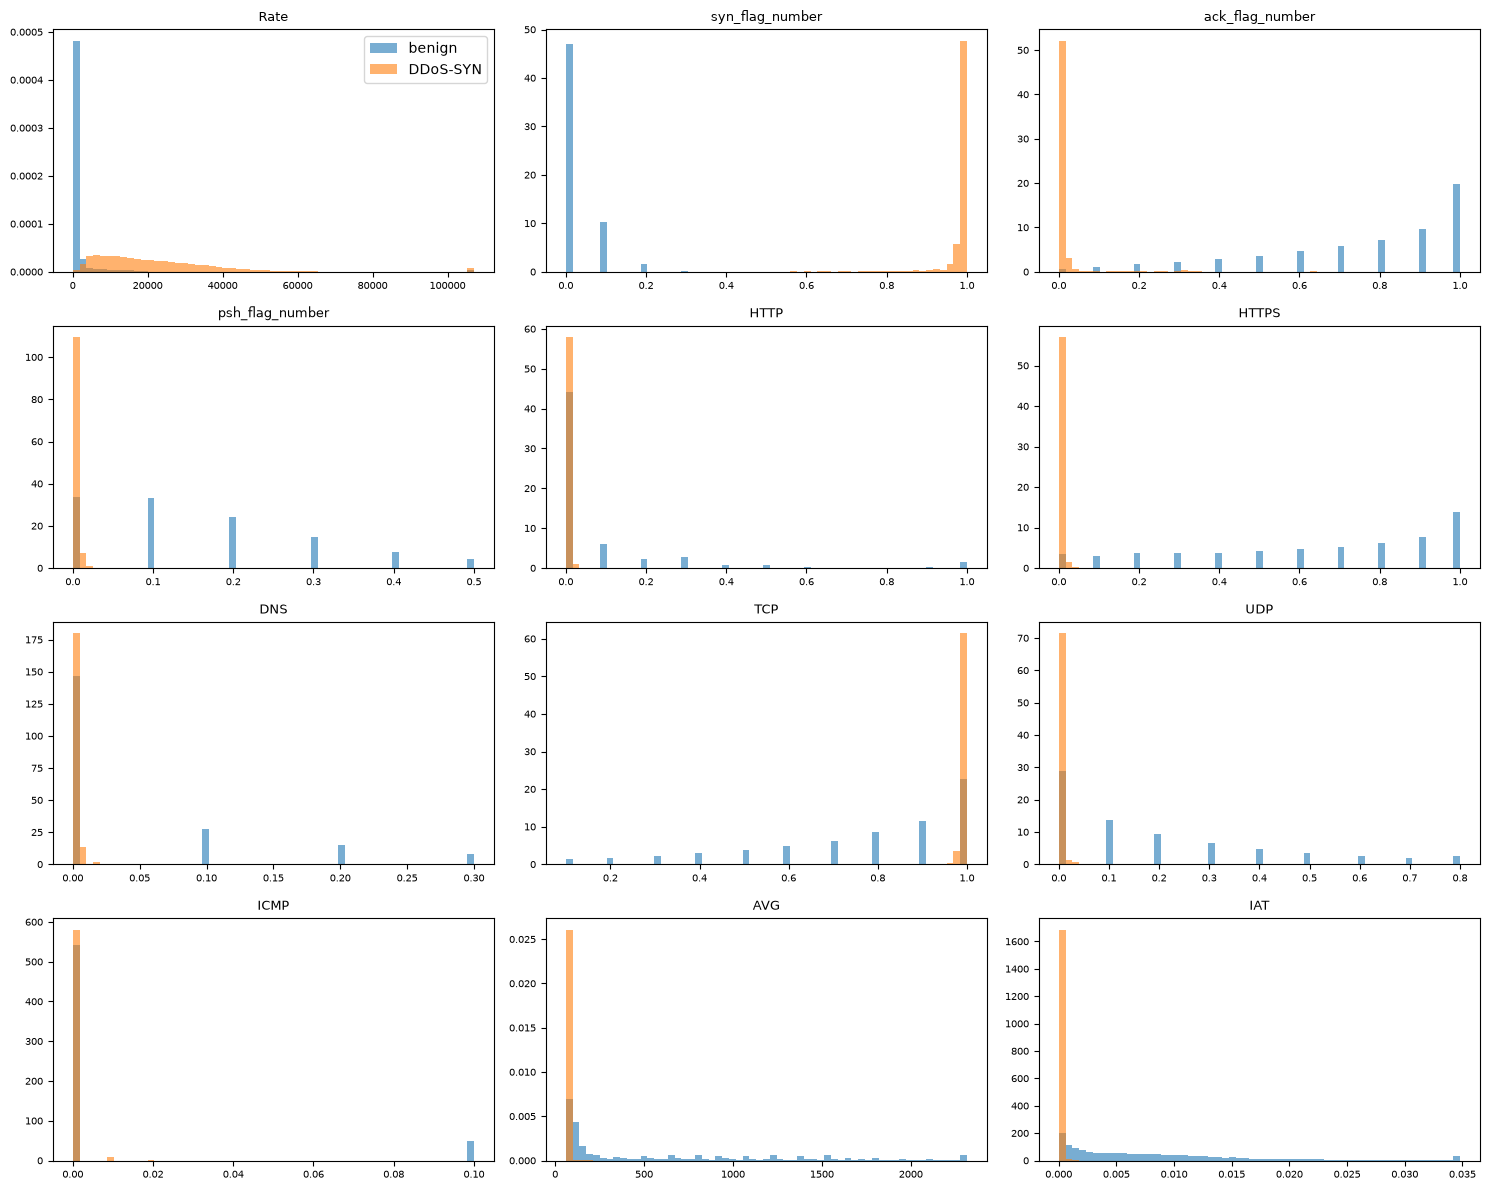

In [8]:
FEATURES = ["Rate", "syn_flag_number", "ack_flag_number", "psh_flag_number",
            "HTTP", "HTTPS", "DNS", "TCP", "UDP", "ICMP", "AVG", "IAT"]

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, feat in zip(axes.flat, FEATURES):
    lo = np.percentile(np.r_[benign_sample[feat], attack_sample[feat]], 1)
    hi = np.percentile(np.r_[benign_sample[feat], attack_sample[feat]], 99)
    bins = np.linspace(lo, hi, 60)
    ax.hist(benign_sample[feat].clip(lo, hi), bins=bins, alpha=0.6, label="benign", density=True)
    ax.hist(attack_sample[feat].clip(lo, hi), bins=bins, alpha=0.6, label="DDoS-SYN", density=True)
    ax.set_title(feat, fontsize=9)
    ax.tick_params(labelsize=7)
axes.flat[0].legend()
plt.tight_layout(); plt.show()

Features that separate this pair cleanly (expect: syn_flag_number, Rate, TCP
protocol share) are candidate rule-engine features for Checkpoint 2. Features
that overlap heavily will need the ML model to earn its keep — that is exactly
the hybrid story of the proposal.

## 7 — second attack pair for contrast (recon vs benign)

recon file: F:\UserData\Downloads\Cerberus\cerberus-core\data\raw\ciciot2023\CSV\Recon-PortScan\Recon-PortScan.pcap.csv


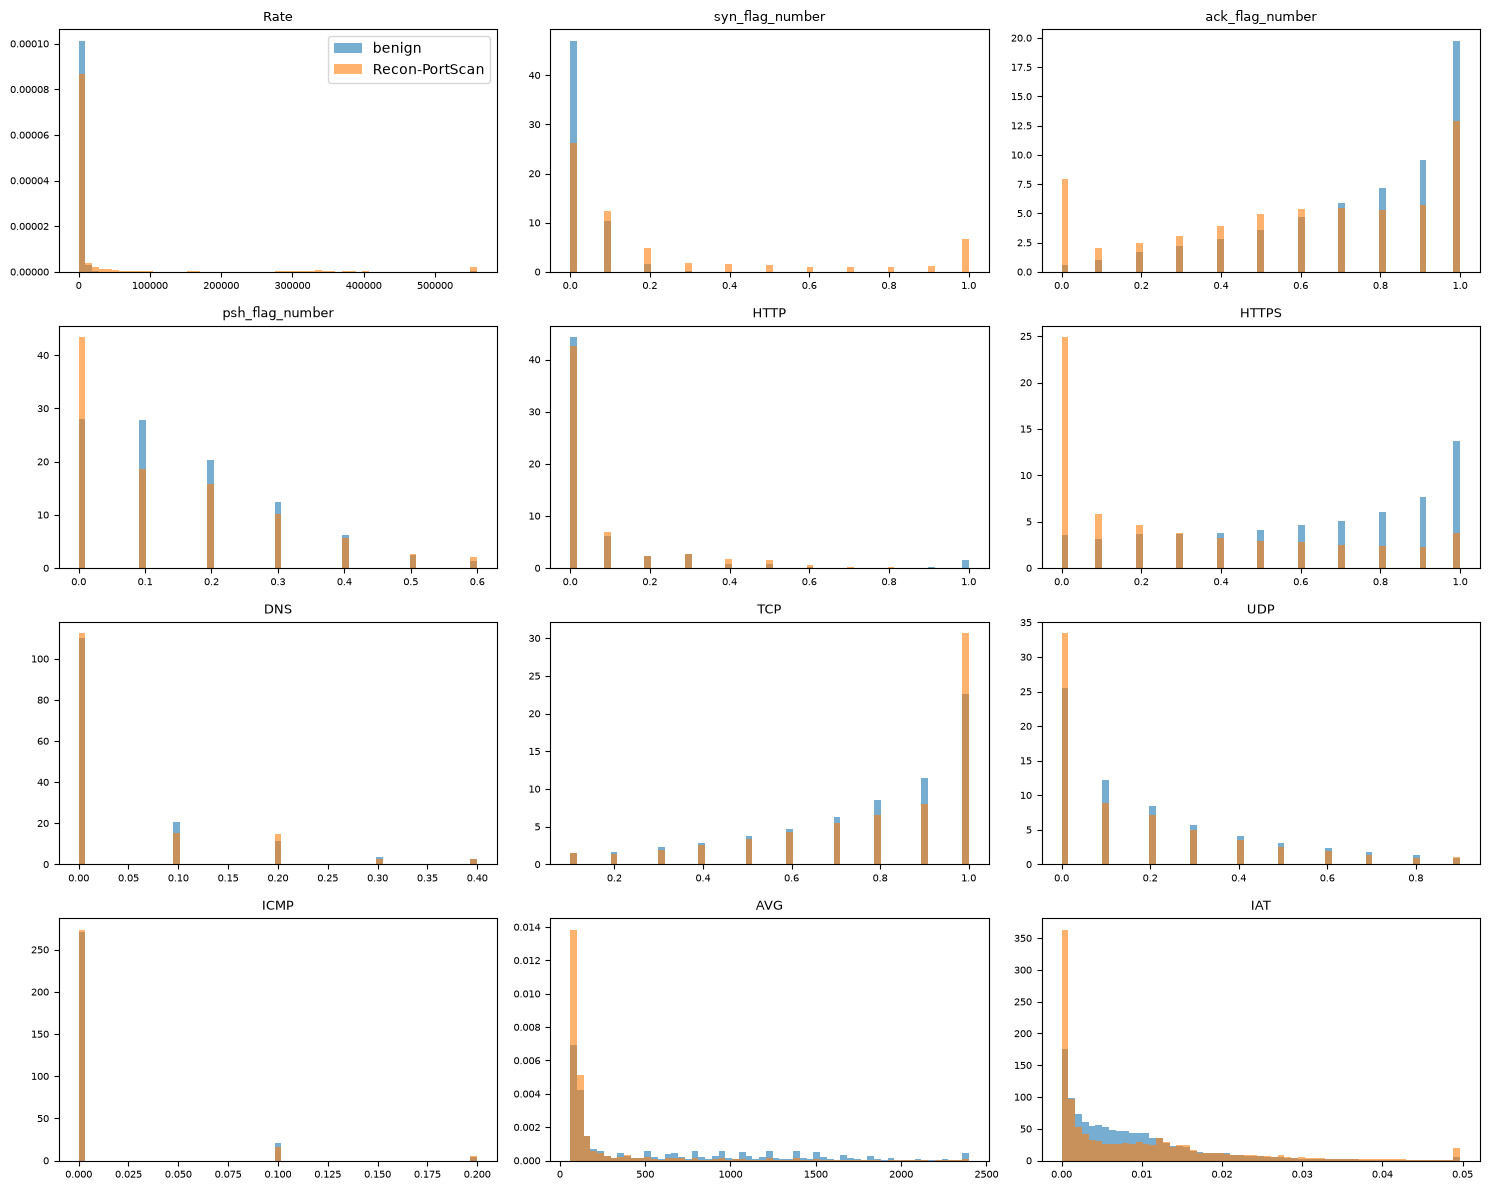

In [9]:
recon_folder = next((ROOT / n for n in ["Recon-PingScan", "Recon-PortScan", "Recon-HostTracker"]
                    if (ROOT / n).is_dir()), None)
recon_file = next(recon_folder.glob("*.csv")) if recon_folder else None
print("recon file:", recon_file)

if recon_file:
    recon_sample = pd.read_csv(recon_file, nrows=50_000)
    fig, axes = plt.subplots(4, 3, figsize=(15, 12))
    for ax, feat in zip(axes.flat, FEATURES):
        lo = np.percentile(np.r_[benign_sample[feat], recon_sample[feat]], 1)
        hi = np.percentile(np.r_[benign_sample[feat], recon_sample[feat]], 99)
        bins = np.linspace(lo, hi, 60)
        ax.hist(benign_sample[feat].clip(lo, hi), bins=bins, alpha=0.6, label="benign", density=True)
        ax.hist(recon_sample[feat].clip(lo, hi), bins=bins, alpha=0.6, label=recon_folder.name, density=True)
        ax.set_title(feat, fontsize=9)
        ax.tick_params(labelsize=7)
    axes.flat[0].legend()
    plt.tight_layout(); plt.show()

Recon traffic mimics benign patterns far more than flooding does — expect much
weaker separation. If true here, it predicts the Checkpoint 2 result: rules
will ace flooding, struggle on recon; the ML model should close part of that
gap. That measured difference IS the paper's benchmark table.

## 8 — summary and decisions carried into Checkpoint 2

In [10]:
print(f"total classes: {len(counts)}, total rows: {int(counts.sum()):,}")
print("benign rows:", int(counts['Benign_Final']))
print("benign share: {:.2%}".format(counts['Benign_Final'] / counts.sum()))

total classes: 34, total rows: 46,776,700
benign rows: 1098191
benign share: 2.35%


Decisions to freeze (fill in after running all cells above):

1. Target classes for OUR testbed benchmark: flooding (DDoS/DoS/Mirai subset)
   + at least one spoofing class (DNS_Spoofing/MITM matches MQTT impersonation
   story) + at least one recon class — enough for rules vs ML vs hybrid to
   differ meaningfully.
2. Class imbalance handling: ____
3. Split policy: leakage-free, folder/file-aware (rows from the same capture
   file never straddle train and test).
4. Feature engineering: none beyond the provided 40 features for v1; MQTT-
   specific features come from OUR simulator/lab traffic instead.
